# Publications over the years

- Data processing for this particular study: we save the publications per years in different files, in data/processed.
- Plot area chart of the publications over the years, for different topics.

In [126]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import itertools
from collections import Counter
import matplotlib.cm as cm
import matplotlib.ticker as ticker

# Base paths for data
DATA = Path("../data")
EXTERNAL = DATA / "external"
PROCESSED = DATA / "processed" / "per_years"
PROCESSED.mkdir(parents=True, exist_ok=True) # create folders if they don't exist

In [ ]:
# CVD-safe palette
colors = {'Social': '#0072B2','Physics': '#E69F00','Life':   '#009E73','Health':    '#CC79A7'} # COLORS ADRI
#colors = [cm.viridis(x) for x in np.linspace(0.1, 0.9, 4)]
#colors = ['#482878', '#31688e', '#35b779', '#fde725'] PER SI DE CAS NO VA

# HEALTH SCIENCE: purple
# PHYSICAL SCIENCES: blue
# LIFE SCIENCES: turquoise
# SOCIAL SCIENCES: yellow

### PRIMARY FILE: papers_cleaned.gencat.parquet

In [5]:
# DATASET: papers_cleaned.gencat.parquet
# Source: Dades obertes de la Generalitat de Catalunya
# Description: cleaned catalan publications
file_path = EXTERNAL / "papers_cleaned.gencat.parquet"

### Load data

In [6]:
def load_local_parquet(path):
    """Carrega un fitxer parquet local."""
    if not path.exists():
        raise FileNotFoundError(f"No s'ha trobat el fitxer: {path}")
    return pd.read_parquet(path)

# Load our data from dataset 'papers_cleaned.gencat.parquet'
df = load_local_parquet(file_path)
print(f"Carregades {len(df)} files.")

Carregades 1747707 files.


### Checks (and exploration)
We do a check and explore the columns/raws we have in our data

In [7]:
def profile(df):
    "To avoid error in the cells where there are lists (authors), we convert them into string"
    df_temp = df.copy()
    # Convert all the columns into strings (to avoid errors in lists, arrays...)
    for col in df_temp.columns:
        try:
            df_temp[col] = df_temp[col].astype(str)
        except Exception:
            pass
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (100 * df.isna().mean()).round(1),
        "n_unique": df_temp.nunique(),
    })

# Print data profile
display(profile(df))
# Print the first raws to explore the data we have
display(df.head())

,dtype,n_missing,pct_missing,n_unique
date,object,0,0.0,11123
doi,object,0,0.0,358039
ruct,object,0,0.0,88888
orcidResearchers,object,0,0.0,824070
orcidUncheckedAuthors,object,1623199,92.9,15920
orcidDirectors,object,1744810,99.8,64


,date,doi,ruct,orcidResearchers,orcidUncheckedAuthors,orcidDirectors
0,1949-01-01T00:00:00.000,10.1210/jcem-9-9-883,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None
1,1952-01-01T00:00:00.000,10.1002/cber.19520850704,Universitat Rovira i Virgili,[0000-0001-6112-5913],None,None
2,1952-01-01T00:00:00.000,10.1111/j.1365-2133.1952.tb15900.x,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None
3,1953-01-01T00:00:00.000,10.1038/jid.1953.55,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None
4,1954-01-01T00:00:00.000,10.1016/s0022-5347(17)67795-4,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None


### Data processing

We separate all the publications in different files per years, and we conserve the following columns: date, DOI.

In [14]:
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year.astype(int) # from the date, we only want the year

# Order years
anys_disponibles = sorted(df['year'].unique())

# Loop to create folders and files per year
for any_pub in anys_disponibles:

    # Filter the rows of this year
    df_any = df[df['year'] == any_pub]

    # Create and save file
    nom_fitxer = f"{any_pub}_publications.parquet"
    ruta_final = PROCESSED / nom_fitxer
    df_any.to_parquet(ruta_final, index=False)
    print(f"Desat: {nom_fitxer} ({len(df_any)} files)")

print(f"\nFet! S'han creat {len(anys_disponibles)} fitxers a la carpeta '{PROCESSED.resolve()}'.")

Desat: 1949_publications.parquet (1 files)
Desat: 1952_publications.parquet (2 files)
Desat: 1953_publications.parquet (1 files)
Desat: 1954_publications.parquet (2 files)
Desat: 1956_publications.parquet (1 files)
Desat: 1957_publications.parquet (1 files)
Desat: 1959_publications.parquet (1 files)
Desat: 1961_publications.parquet (2 files)
Desat: 1962_publications.parquet (3 files)
Desat: 1964_publications.parquet (1 files)
Desat: 1966_publications.parquet (1 files)
Desat: 1967_publications.parquet (1 files)
Desat: 1969_publications.parquet (6 files)
Desat: 1970_publications.parquet (36 files)
Desat: 1972_publications.parquet (7 files)
Desat: 1973_publications.parquet (14 files)
Desat: 1974_publications.parquet (19 files)
Desat: 1975_publications.parquet (18 files)
Desat: 1976_publications.parquet (26 files)
Desat: 1977_publications.parquet (41 files)
Desat: 1978_publications.parquet (51 files)
Desat: 1979_publications.parquet (87 files)
Desat: 1980_publications.parquet (126 files)
D

### PLOT 1: all publications over the years

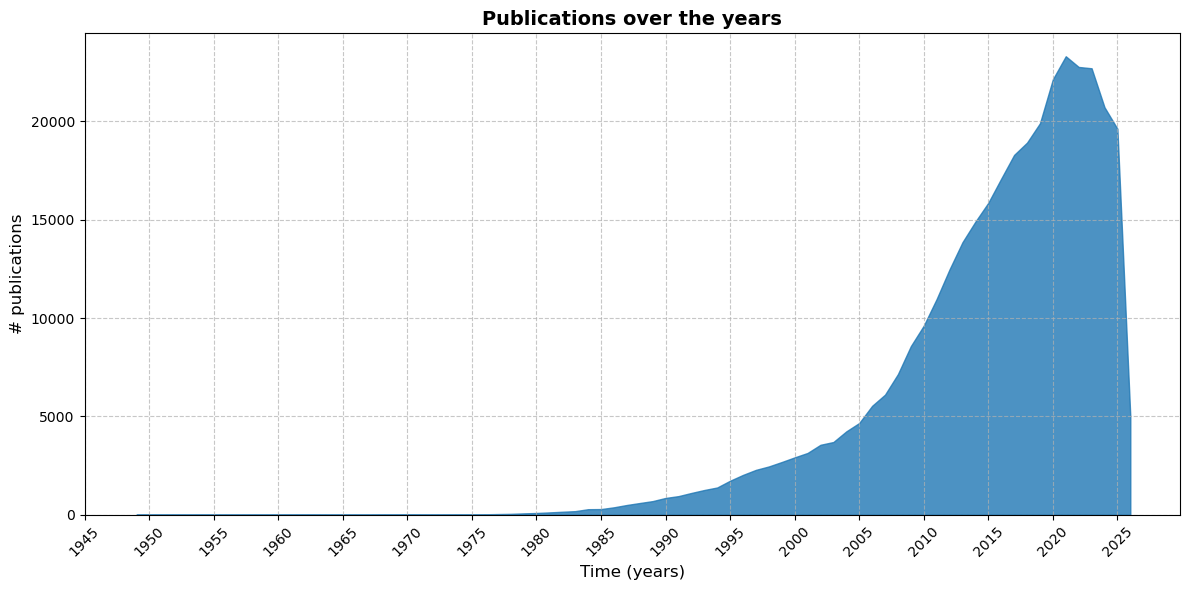

In [9]:
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year.astype(int) # from the date, we only want the year

# FILTER DUPLICATED DOIS-----------------------------------------------
df_unics = df.drop_duplicates(subset=["doi"])
#----------------------------------------------------------------------

# Counts publications per year
publicacions_per_any = df_unics['year'].value_counts().sort_index()

anys = publicacions_per_any.index
quantitat = publicacions_per_any.values

# PLOT
plt.figure(figsize=(12, 6))
plt.stackplot(anys, quantitat, labels=['Total publicacions'], color='#1f77b4', alpha=0.8)
plt.title("Publications over the years", fontsize=14, fontweight='bold')
plt.xlabel("Time (years)", fontsize=12)
plt.ylabel("# publications", fontsize=12)
ticks_anys = np.arange(1945, max(anys) + 1, 5)
plt.xticks(ticks_anys, rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
#plt.legend(loc='upper left')
plt.tight_layout()

plt.show()

### SECONDARY FILES: fields.parquet, works.parquet

In [10]:
# FIELDS (fields.parquet)

fields_df = pd.read_parquet("../data/external/fields.parquet")

print("Columnes:", fields_df.columns.tolist())
print(f"Dimensions: {fields_df.shape[0]} files i {fields_df.shape[1]} columnes")

#display(fields_df.head()) # shows firsts raws
display(fields_df) # shows all raws 26)

Columnes: ['field_id', 'field_name', 'domain_id', 'domain_name']
Dimensions: 26 files i 4 columnes


,field_id,field_name,domain_id,domain_name
0,33,Social Sciences,2,Social Sciences
1,31,Physics and Astronomy,3,Physical Sciences
2,27,Medicine,4,Health Sciences
3,12,Arts and Humanities,2,Social Sciences
4,11,Agricultural and Biological Sciences,1,Life Sciences
5,22,Engineering,3,Physical Sciences
6,17,Computer Science,3,Physical Sciences
7,23,Environmental Science,3,Physical Sciences
8,14,"Business, Management and Accounting",2,Social Sciences
9,13,"Biochemistry, Genetics and Molecular Biology",1,Life Sciences


In [23]:
# WORKS (works.parquet)

works_df = pd.read_parquet("../data/external/works.parquet")

print(f"Dimensions: {works_df.shape[0]} files, {works_df.shape[1]} columnes")
print("Columnes:", works_df.columns.tolist())

display(works_df.head(2))

Dimensions: 348417 files, 9 columnes
Columnes: ['openalex_id', 'doi', 'apc_paid_value_usd', 'apc_list_value_usd', 'awards', 'funders', 'primary_topic_field_id', 'topics_field_ids', 'referenced_works']


,openalex_id,doi,apc_paid_value_usd,apc_list_value_usd,awards,funders,primary_topic_field_id,topics_field_ids,referenced_works
0,W2052543964,10.1021/ja01036a083,NaN,4500.0,[],[],16,[],[]
1,W2917211058,10.1016/j.patrec.2019.02.029,NaN,2550.0,[],[],17,[],[]


### Cross data

In [80]:
PROCESSED = Path("../data/processed")
PER_YEARS = PROCESSED / "per_years"

# Join all files per years in one temporary variable called df_total
llista_dfs = [pd.read_parquet(f) for f in PER_YEARS.glob("*_publications.parquet")]
df_total = pd.concat(llista_dfs, ignore_index=True)

# FILTER DUPLICATED DOIS-----------------------------------------------
total_files_originals = len(df_total)
dois_unics_originals = df_total["doi"].nunique()
duplicats_originals = total_files_originals - dois_unics_originals

print(f"Files originals: {total_files_originals}")
print(f"DOIs únics: {dois_unics_originals}")
print(f"Duplicats detectats a l'origen: {duplicats_originals}")
# ---------------------------------------------------------------------

df_total_unics = df_total.drop_duplicates(subset=["doi"])
print("Dois unics drop duplicates", len(df_total_unics))

# Load data (fields, domains..)
works = pd.read_parquet("../data/external/works.parquet", columns=["doi", "primary_topic_field_id", "topics_field_ids"])
fields = pd.read_parquet("../data/external/fields.parquet")

work_temporal = works.drop_duplicates(subset=["doi"])
total_works_temporal = len(work_temporal)
print("TOTAL WORKS",len(works))
print("Total NO DUPLICATS de works:",total_works_temporal)
print("Duplicats works",len(works)-total_works_temporal)

# Force that IDs are text to merge them correctly
works["primary_topic_field_id"] = works["primary_topic_field_id"].astype(str)
fields["field_id"] = fields["field_id"].astype(str)

# Create diccionaries to traduce IDs into names
field_to_domain = dict(zip(fields["field_id"], fields["domain_name"]))
field_to_name = dict(zip(fields["field_id"], fields["field_name"]))

# Merge works to the df_total (doi,date)
df_complet = df_total_unics.merge(work_temporal, on="doi", how="left",validate="one_to_one") # merge 'left' to conserve all papers
print("TOTAL MERGED:", len(df_complet))

Files originals: 1747707
DOIs únics: 358039
Duplicats detectats a l'origen: 1389668
Dois unics drop duplicates 358039
TOTAL WORKS 348417
Total NO DUPLICATS de works: 347999
Duplicats works 418
TOTAL MERGED: 358039


In [79]:
# Add domains and topics names
df_complet["domain_name"] = df_complet["primary_topic_field_id"].map(field_to_domain)
df_complet["field_name"] = df_complet["primary_topic_field_id"].map(field_to_name)

# Select only the columns we want
columnes_finals = ["year", "doi", "domain_name", "field_name", "topics_field_ids"]
df_final = df_complet[columnes_finals]

# Save the file: all_publications_enriched.parquet
output_path = PROCESSED / "all_publications_enriched_new.parquet"
df_final.to_parquet(output_path, index=False)

print(f"Dimensions: {df_final.shape[0]} files, {df_final.shape[1]} columnes")
print(f"Columnes: {df_final.columns.tolist()}")

# Count papers with and without topic and print nums
total_papers = len(df_final)
papers_sense_topic = df_final["domain_name"].isna().sum()
papers_amb_topic = total_papers - papers_sense_topic

print(f"Total de papers (sense tocar res): {total_papers}")
print(f"Papers SENSE topic assignat: {papers_sense_topic}")
print(f"Papers AMB topic assignat: {papers_amb_topic}")
print(f"Percentatge de papers sense topic: {(papers_sense_topic / total_papers) * 100:.2f}%")

Dimensions: 358039 files, 5 columnes
Columnes: ['year', 'doi', 'domain_name', 'field_name', 'topics_field_ids']
Total de papers (sense tocar res): 358039
Papers SENSE topic assignat: 12313
Papers AMB topic assignat: 345726
Percentatge de papers sense topic: 3.44%


### PLOT 2: Publications over the years per domain

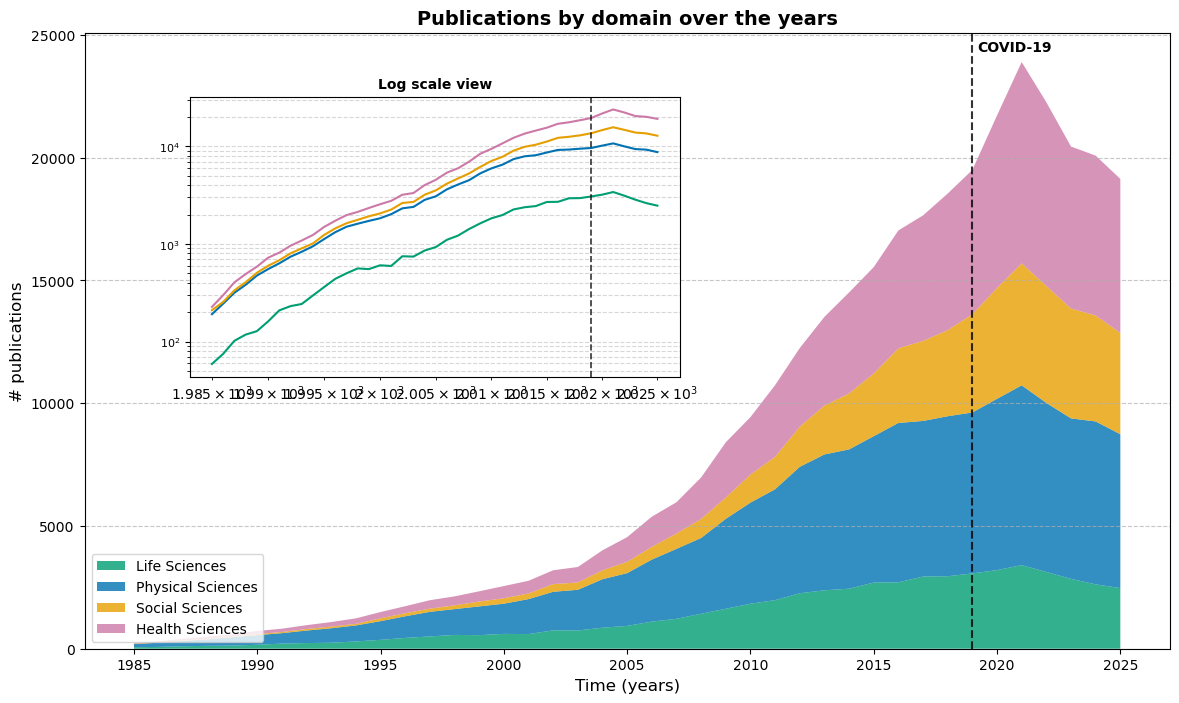

In [94]:
df = pd.read_parquet("../data/processed/all_publications_enriched_new.parquet")
colors = {'Life Sciences': '#009E73','Physical Sciences': '#0072B2','Social Sciences': '#E69F00','Health Sciences': '#CC79A7'}
# Only papers with domain assigned
df_plots = df.dropna(subset=["domain_name"])

# Eliminate DOI duplicated publications
#df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

# Create table for the plot: Files = Anys, Columnes = Dominis, Valors = Nombre de papers
taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)

order = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[order] # Apliquem l'ordre a les columnes

# FILTER THE YEARS AFTER 1980 and BEFORE 2025
taula_dominis = taula_dominis[(taula_dominis.index >= 1985) & (taula_dominis.index <= 2025)]

anys = taula_dominis.index
quantitats = [taula_dominis[col].values for col in taula_dominis.columns]
etiquetes = taula_dominis.columns.tolist()

colors_list = [colors[col] for col in etiquetes]

cumsum = taula_dominis.cumsum(axis=1)

# PLOT
#plt.figure(figsize=(12, 6))
#plt.stackplot(anys, quantitats, labels=etiquetes, alpha=0.8)
#plt.title("Publications by domain over the years per domains", fontsize=14, fontweight='bold')
#plt.xlabel("Time (years)", fontsize=12)
#plt.ylabel("# publications", fontsize=12)
#plt.grid(axis='y', linestyle='--', alpha=0.7)
#plt.legend(loc='upper left') # Aquí sí que posem la llegenda perquè hi ha 4 colors!
#plt.tight_layout()

# PLOT
fig = plt.figure(figsize=(14, 8)) # He fet la figura una mica més gran
ax_main = fig.add_subplot(111)   # Aquest serà el gràfic gran
ax_main.stackplot(anys, quantitats, labels=etiquetes, colors=colors_list, alpha=0.8)
ax_main.set_title("Publications by domain over the years", fontsize=14, fontweight='bold')
ax_main.set_xlabel("Time (years)", fontsize=12)
ax_main.set_ylabel("# publications", fontsize=12)
ax_main.grid(axis='y', linestyle='--', alpha=0.7)
ax_main.legend(loc='lower left')

# Line to indicate COVID-19
ax_main.axvline(x=2019, color='black', linestyle='--', linewidth=1.5, alpha=0.8)
ax_main.text(2019.2, ax_main.get_ylim()[1]*0.97, 'COVID-19', color='black', fontsize=10, fontweight='bold')

# Inset
ax_inset = fig.add_axes([0.2, 0.45, 0.35, 0.35]) 
for i, col in enumerate(cumsum.columns):
    ax_inset.plot(anys, cumsum[col], color=colors_list[i], linewidth=1.5)
ax_inset.set_yscale('log')
ax_inset.set_xscale('log')
ax_inset.set_title("Log scale view", fontsize=10, fontweight='bold')
ax_inset.grid(axis="y", linestyle='--', alpha=0.5, which='both') # 'both' inclou les línies de la graella logarítmica
ax_inset.tick_params(axis='both', labelsize=8)
# Line to indicate COVID-19 in the inset
ax_inset.axvline(x=2019, color='black', linestyle='--', linewidth=1.2, alpha=0.8)

# SAVE PLOT
output_dir = "../plots/alba"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/area_chart_publications_by_domain.png", dpi=300, bbox_inches='tight')

plt.show()

COMMENTS:

- Linear regression has been generated by the python function, and according to the TOTAL of publications (upper line, because it is the total sum of all domains). The data used for the regression are the marked points.

COSES A FER A AQUEST GRÀFIC:
- amb el grafic darees, veig una explosio de publicacions i vull saber com es aquest creixement exponencial  (--> faig log log per caracteritzarho). també veig que cap al 2020 hi ha un canvi altre creixement (--> miro per mesos exactament què passa) --> per veure millor, faig un requadre a efectes covid?
- amb el grafic log log trec els efectes de l'escala (ferho amb punts per pintar els que faig servir per a la regressio i recta regressio en vermell flotant a dalt) --> equacio exp(coef*x^alfa) --> he de trobar lalfa per saber quin es el creixement que té i amb el coef ajusto com d'amunt poso la recta. també puc veure lexces en el moment del covid.
- amb el grafic del covid (2019,2020,2021,2022) per mesos faig el mateix estudi i faig una casella al lockdown --> puc mirar el retard del creixement de les publicacions (i potser donar dades daquest creixemnet fent grafic log, o no)

LLEGENDA:
- gràfic log --> e^x
- gràfic log-log --> e^(x^alfa)

NameError: name 'LogFormatterMathtext' is not defined

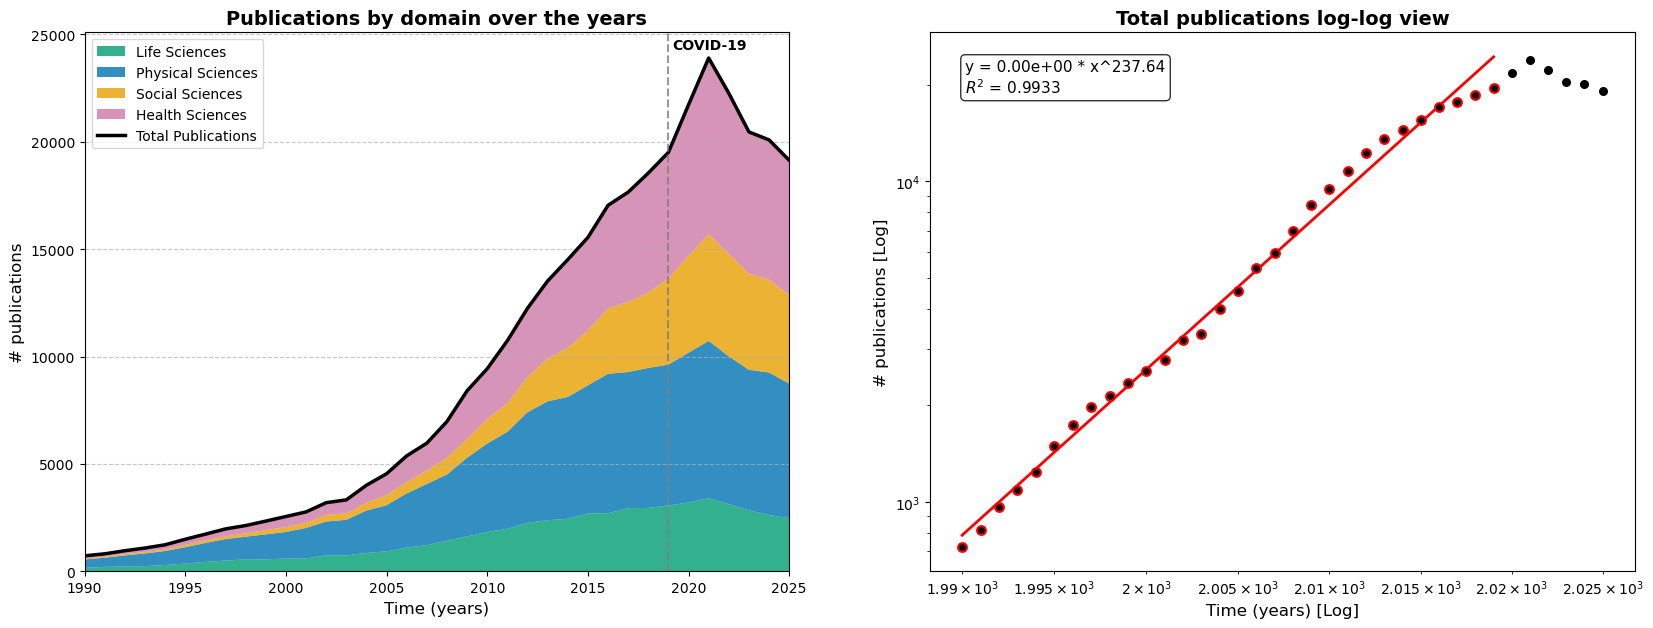

In [128]:
df = pd.read_parquet("../data/processed/all_publications_enriched_new.parquet")
colors = {'Life Sciences': '#009E73','Physical Sciences': '#0072B2','Social Sciences': '#E69F00','Health Sciences': '#CC79A7'}
df_plots = df.dropna(subset=["domain_name"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
order = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[order]
taula_dominis = taula_dominis[(taula_dominis.index >= 1990) & (taula_dominis.index <= 2025)]

anys = taula_dominis.index
quantitats = [taula_dominis[col].values for col in taula_dominis.columns]
etiquetes = taula_dominis.columns.tolist()
colors_list = [colors[col] for col in etiquetes]

# Total publications per year
total_per_any = taula_dominis.sum(axis=1)
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(20, 7))

# PLOT LEFT-------------------------------------------------------------------------
ax_left.stackplot(anys, quantitats, labels=etiquetes, colors=colors_list, alpha=0.8)
line_total, = ax_left.plot(anys, total_per_any, color='#000000', linewidth=2.5, label='Total Publications')
## ax_left.plot(anys, total_per_any, color='#000000', linewidth=2.5, label='Total Publications')
ax_left.set_title("Publications by domain over the years", fontsize=14, fontweight='bold')
ax_left.set_xlabel("Time (years)", fontsize=12)
ax_left.set_ylabel("# publications", fontsize=12)
ax_left.grid(axis='y', linestyle='--', alpha=0.7)
ax_left.set_xlim(anys.min(), anys.max())

# Manual legend to introduce total of publications
handles, labels = ax_left.get_legend_handles_labels()
handles.append(line_total)
labels.append('Total Publications')

## ax_left.legend(handles=handles, labels=labels, loc='upper left')
ax_left.legend(loc='upper left')
ax_left.axvline(x=2019, color='gray', linestyle='--', linewidth=1.5, alpha=0.8)
ax_left.text(2019.2, ax_left.get_ylim()[1]*0.97, 'COVID-19', color='black', fontsize=10, fontweight='bold')

# PLOT RIGHT------------------------------------------------------------------------
ax_right.scatter(anys, total_per_any, color='#000000', s=30, label='Total Publications')

# LINEAR REGRESSION from 1990 fins tp 2019
mask = (anys >= 1990) & (anys <= 2019)
anys_reg = anys[mask]
total_reg = total_per_any[mask]

#ax_right.scatter(anys[mask], total_per_any[mask], color='red', s=40, edgecolor='white', zorder=3, label='Data used for regression')
ax_right.scatter(anys[mask], total_per_any[mask], color='#000000', edgecolor='red', linewidths=1.5, s=40, zorder=3, label='Data used for regression')

log_anys = np.log10(anys_reg) # Linear regression: log(y) = m * log(x) + b, so we adapt that
log_total = np.log10(total_reg)

# Fit (m and b calculus)
m, b = np.polyfit(log_anys, log_total, 1)

# R^2 calculus
total_pred = m * log_anys + b
ss_res = np.sum((log_total - total_pred) ** 2)
ss_tot = np.sum((log_total - np.mean(log_total)) ** 2)
r_squared = 1 - (ss_res / ss_tot)

# Linear regression
x_fit = np.linspace(min(log_anys), max(log_anys), 100)
y_fit = m * x_fit + b
ax_right.plot(10**x_fit, 10**y_fit, color='red', linewidth=2, label='Linear Regression (1990-2019)')

text_eq = f"y = {10**b:.2e} * x^{m:.2f}\n$R^2$ = {r_squared:.4f}"
ax_right.text(0.05, 0.95, text_eq, transform=ax_right.transAxes, fontsize=11,
             verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax_right.set_xscale('log')
ax_right.set_yscale('log')
ax_right.set_title("Total publications log-log view", fontsize=14, fontweight='bold')
ax_right.set_xlabel("Time (years) [Log]", fontsize=12)
ax_right.set_ylabel("# publications [Log]", fontsize=12)
ax_right.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
ax_right.yaxis.set_minor_formatter(LogFormatterMathtext(base=10))
ax_right.grid(True, linestyle='--', alpha=0.5, which='both')
ax_right.legend(loc='lower right')
plt.tight_layout()

# Save plots
output_dir = "../plots/alba"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/publications_comparison_with_regression.png", dpi=300, bbox_inches='tight')

plt.show()

We can see a peak in 2021 (year right after COVID-19, so probably when articles written during locked down were published) and we want to see the contributions of each domain to it, so, for each domain, we normalize the publications over its total publications (if at one domain has in total 10000 papers and in one year there are 50, then the)

Al voltant del 1990, es fan les primeres publicacions online (a traves de revistes online).

### PLOT 3: Normalized publications over the years per domains

NORMALITZACIO: $$Norm = \frac{H-<H>}{<H>}$$

- $H$ --> nombre de publicacions del domini en un determinat any
- $<H>$ --> mitjana de publicacions del domini al llarg dels anys

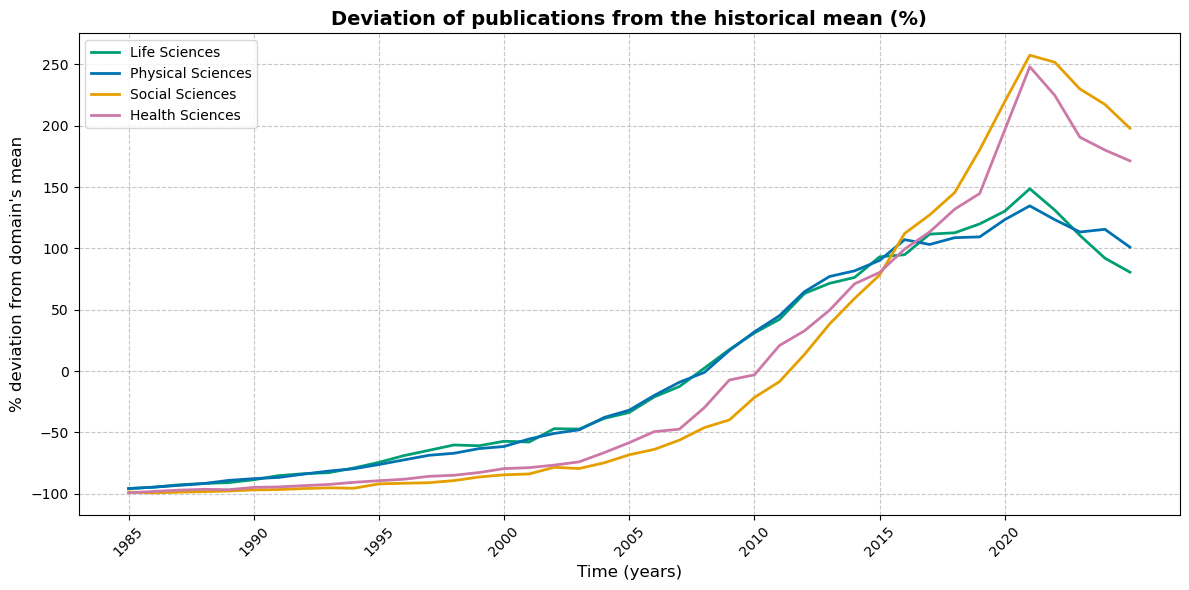

In [91]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

colors = {'Life Sciences': '#009E73','Physical Sciences': '#0072B2','Social Sciences': '#E69F00','Health Sciences': '#CC79A7'}

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)

# Reorder the domains
ordre_desitjat = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[ordre_desitjat]

# FILTER THE YEARS AFTER 1980 and BEFORE 2025
taula_dominis = taula_dominis[(taula_dominis.index >= 1985) & (taula_dominis.index <= 2025)]

# NORMALIZATION (Any - Mitjana) / Mitjana
# Calculem la mitjana de cada columna
mitjanes = taula_dominis.mean(axis=0)

# Restem la mitjana i dividim per la mitjana, i ho passem a percentatge (* 100)
taula_normalitzada = ((taula_dominis - mitjanes) / mitjanes) * 100

anys = taula_normalitzada.index

# PLOT
plt.figure(figsize=(12, 6))
for i, col in enumerate(taula_normalitzada.columns):
    plt.plot(anys, taula_normalitzada[col], label=col, linewidth=2, color=colors[col])
plt.title("Deviation of publications from the historical mean (%)", fontsize=14, fontweight='bold')
plt.xlabel("Time (years)", fontsize=12)
plt.ylabel("% deviation from domain's mean", fontsize=12) 

# Horitzontal axis to 0 --> mean
#plt.axhline(0, color='black', linewidth=1.5, linestyle='--')
plt.grid(True, linestyle='--', alpha=0.7)
ticks_anys = np.arange(1985,2025, 5)
plt.xticks(ticks_anys, rotation=45)
plt.legend(loc='upper left')
plt.tight_layout()

# SAVE PLOT
output_dir = "../plots/alba"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/deviation_publications_from_history.png", dpi=300, bbox_inches='tight')

plt.show()

### CONTRIBUCIÓ RELATIVA

NORMALITZACIO: $$Norm = \frac{H-<H>}{<T>}$$

- $H$ --> nombre de publicacions del domini en un determinat any
- $<H>$ --> mitjana de publicacions del domini al llarg dels anys
- $<T>$ --> mitjana de publicacions total al llarg dels anys

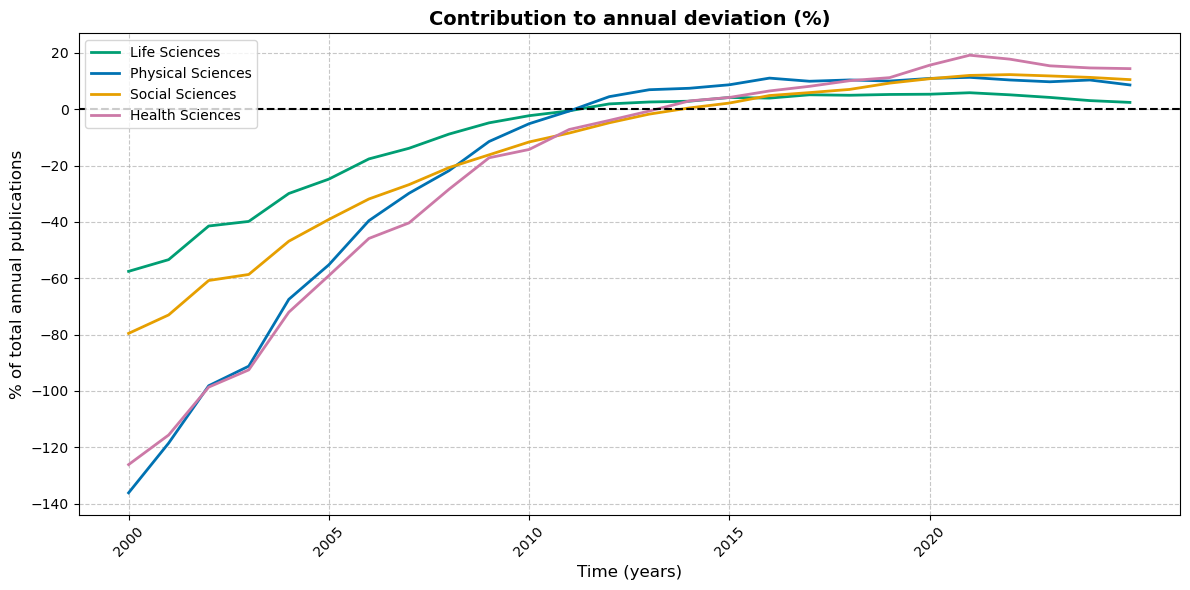

In [92]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)

ordre_desitjat = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[ordre_desitjat]

taula_dominis = taula_dominis[(taula_dominis.index >= 2000) & (taula_dominis.index <= 2025)]

# 1. Calculem la mitjana de cada domini
mitjanes = taula_dominis.mean(axis=0)

# 2. Calculem la desviació (Papers de l'any - Mitjana)
desviacio = taula_dominis - mitjanes

# 3. 🆕 NOVA NORMALITZACIÓ: Dividim la desviació pel total de papers d'aquell any
total_anual = taula_dominis.sum(axis=1)
taula_normalitzada = desviacio.div(total_anual, axis=0) * 100

anys = taula_normalitzada.index

# PLOT
plt.figure(figsize=(12, 6))
colors = {'Life Sciences': '#009E73','Physical Sciences': '#0072B2','Social Sciences': '#E69F00','Health Sciences': '#CC79A7'}

for i, col in enumerate(taula_normalitzada.columns):
    plt.plot(anys, taula_normalitzada[col], label=col, linewidth=2, color=colors[col])

plt.title("Contribution to annual deviation (%)", fontsize=14, fontweight='bold')
plt.xlabel("Time (years)", fontsize=12)
plt.ylabel("% of total annual publications", fontsize=12) 

# Línia horitzontal al 0
plt.axhline(0, color='black', linewidth=1.5, linestyle='--')
plt.grid(True, linestyle='--', alpha=0.7)

ticks_anys = np.arange(2000, 2025, 5)
plt.xticks(ticks_anys, rotation=45)
plt.legend(loc='upper left')
plt.tight_layout()

# SAVE PLOT
output_dir = "../plots/alba"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/deviation_relative_to_total.png", dpi=300, bbox_inches='tight')

plt.show()

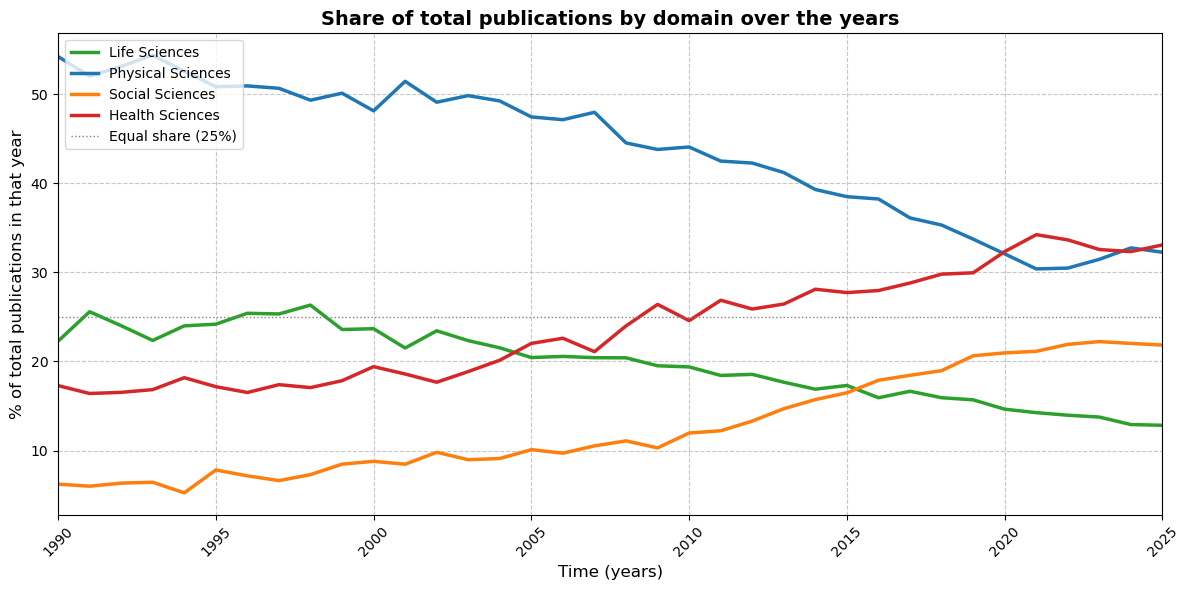

In [49]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)

# Reordenem els dominis
ordre_desitjat = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[ordre_desitjat]

# 🆕 NORMALITZACIÓ OPCIÓ 2: Dividir pel total de papers d'aquell any
# .div(..., axis=0) divideix cada fila (any) per la seva suma total
taula_percentatges = taula_dominis.div(taula_dominis.sum(axis=1), axis=0) * 100

# 🆕 FILTRE D'ANYS: DE 1990 A 2025
taula_percentatges = taula_percentatges[(taula_percentatges.index >= 1990) & (taula_percentatges.index <= 2025)]

anys = taula_percentatges.index

# PLOT
plt.figure(figsize=(12, 6))
colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728'] 

for i, col in enumerate(taula_percentatges.columns):
    plt.plot(anys, taula_percentatges[col], label=col, linewidth=2.5, color=colors[i])

plt.title("Share of total publications by domain over the years", fontsize=14, fontweight='bold')
plt.xlabel("Time (years)", fontsize=12)
plt.ylabel("% of total publications in that year", fontsize=12) 
# Posem una línia horitzontal al 25% (que seria el repartiment perfecte si tots 4 dominis publiquessin igual)
plt.axhline(25, color='gray', linewidth=1, linestyle=':', label='Equal share (25%)')

plt.grid(True, linestyle='--', alpha=0.7)

# 🆕 ELS TICKS DE L'EIX X DE 5 EN 5 COMENÇANT AL 1990
ticks_anys = np.arange(1990, 2026, 5)
plt.xticks(ticks_anys, rotation=45)

# 🆕 FORCEM ELS LÍMITS PERQUÈ NO QUEDIN ESPAIS EN BLANC
plt.xlim(1990, 2025)

# Anys de 5 en 5
#ticks_anys = np.arange(1945, max(anys) + 1, 5)
#plt.xticks(ticks_anys, rotation=45)
plt.legend(loc='upper left')
plt.tight_layout()

plt.show()

### PLOT 4: Publications over the years per domains in different plots (després per Topics)

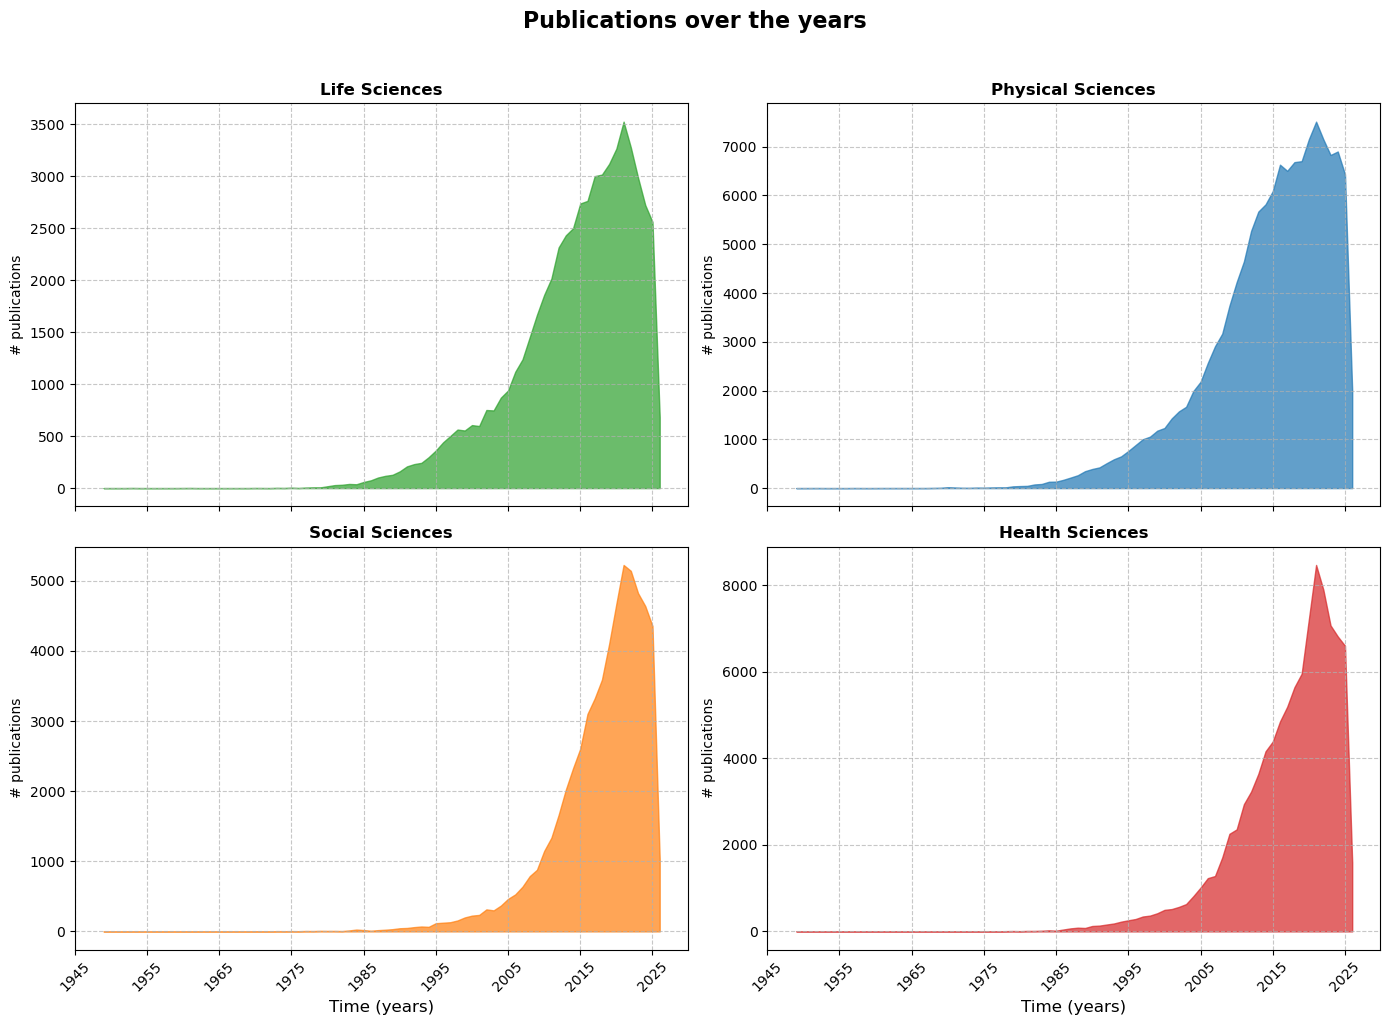

In [ ]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)

order = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[order]

anys = taula_dominis.index

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10), sharex=True)
axes = axes.flatten()

colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']

for i, domini in enumerate(order):
    ax = axes[i]
    ax.fill_between(anys, taula_dominis[domini], color=colors[i], alpha=0.7, label=domini)
    ax.set_title(domini, fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.set_ylabel("# publications")
    ticks_anys = np.arange(1945, max(anys) + 1, 10)
    ax.set_xticks(ticks_anys)

fig.suptitle("Publications over the years", fontsize=16, fontweight='bold', y=1.02)
axes[2].set_xlabel("Time (years)", fontsize=12)
axes[3].set_xlabel("Time (years)", fontsize=12)
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

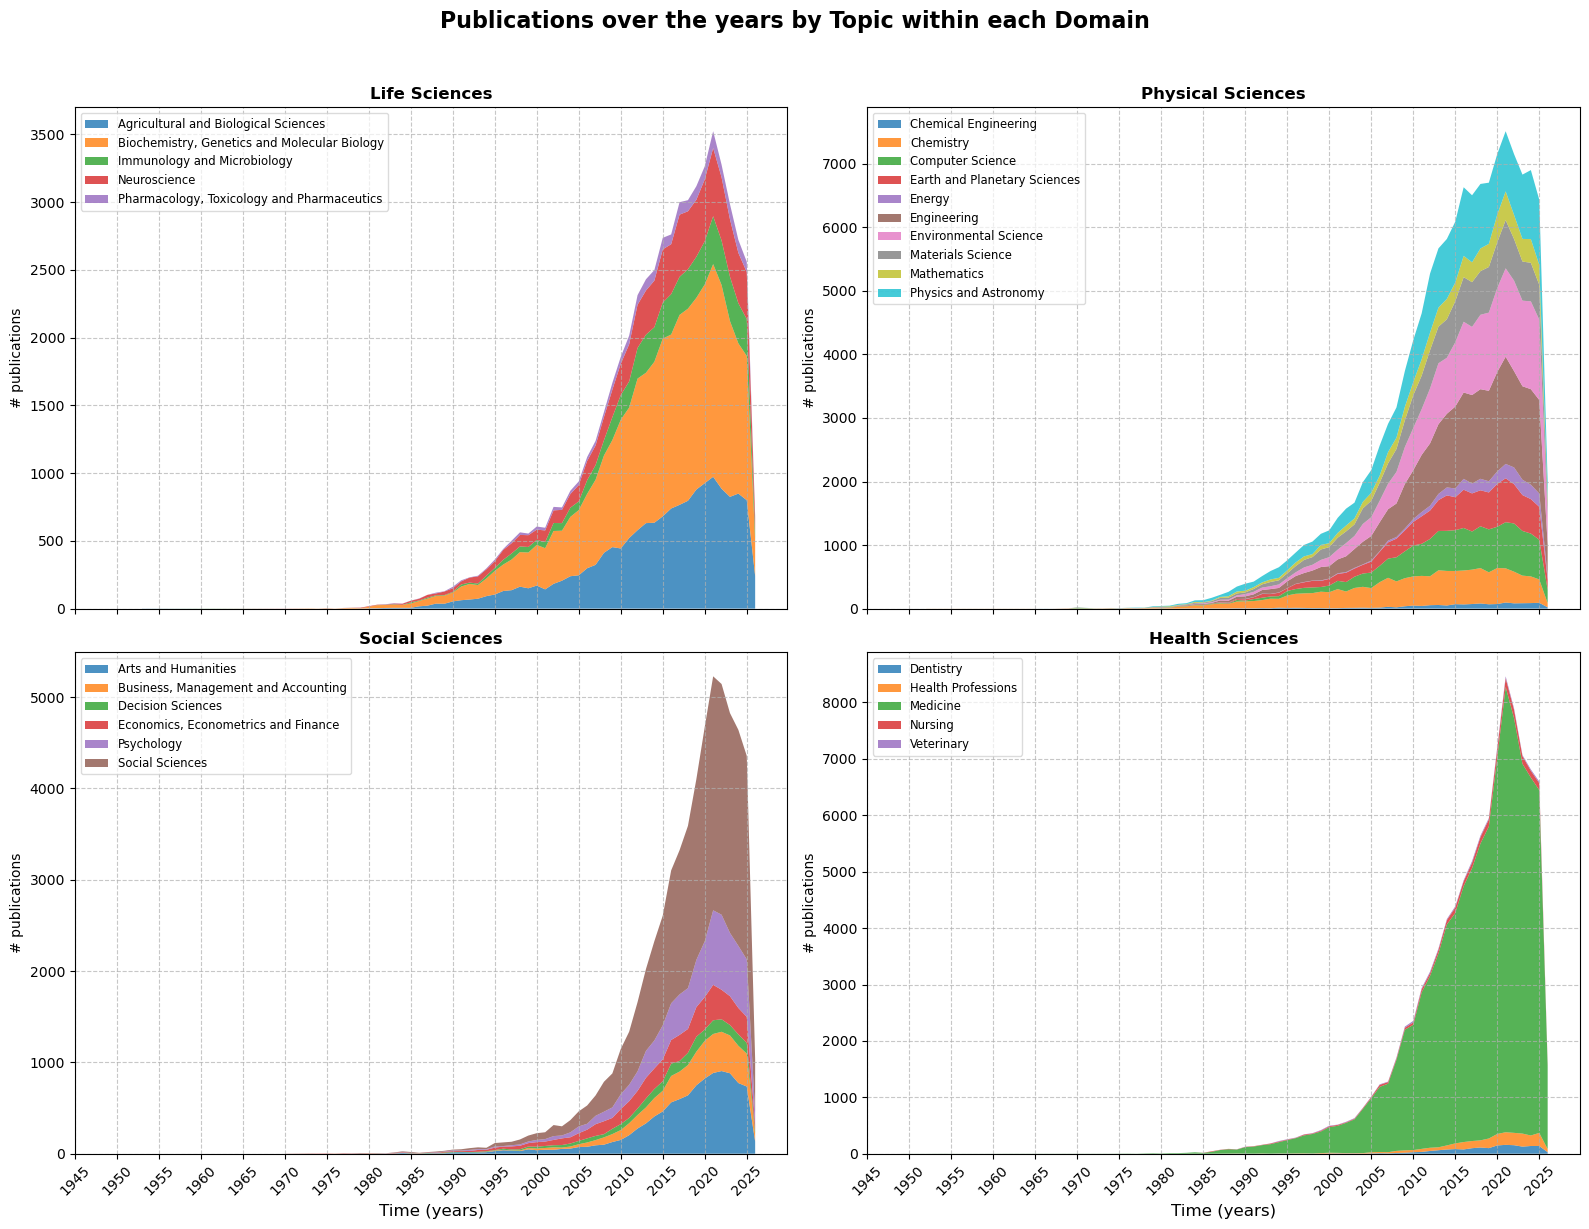

In [44]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name", "field_name"]) # Assegurem que tenim tots dos
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12), sharex=True)
axes = axes.flatten()

order_domains = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]

for i, domini in enumerate(order_domains):
    ax = axes[i]

    df_dom = df_plots[df_plots["domain_name"] == domini]
    taula_topics = df_dom.groupby(["year", "field_name"]).size().unstack(fill_value=0)

    # If we only want the 5 most famous topics
    #top_topics = taula_topics.sum().nlargest(5).index
    #taula_topics = taula_topics[top_topics]
    
    anys = taula_topics.index
    quantitats = [taula_topics[col].values for col in taula_topics.columns]
    etiquetes = taula_topics.columns.tolist()
    ax.stackplot(anys, quantitats, labels=etiquetes, alpha=0.8)
    ax.set_title(f"{domini}", fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.set_ylabel("# publications")
    ticks_anys = np.arange(1945, max(anys) + 1, 5)
    ax.set_xticks(ticks_anys)
    ax.legend(loc='upper left', fontsize='small', framealpha=0.7)

fig.suptitle("Publications over the years by Topic within each Domain", fontsize=16, fontweight='bold', y=1.02)

axes[2].set_xlabel("Time (years)", fontsize=12)
axes[3].set_xlabel("Time (years)", fontsize=12)

for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

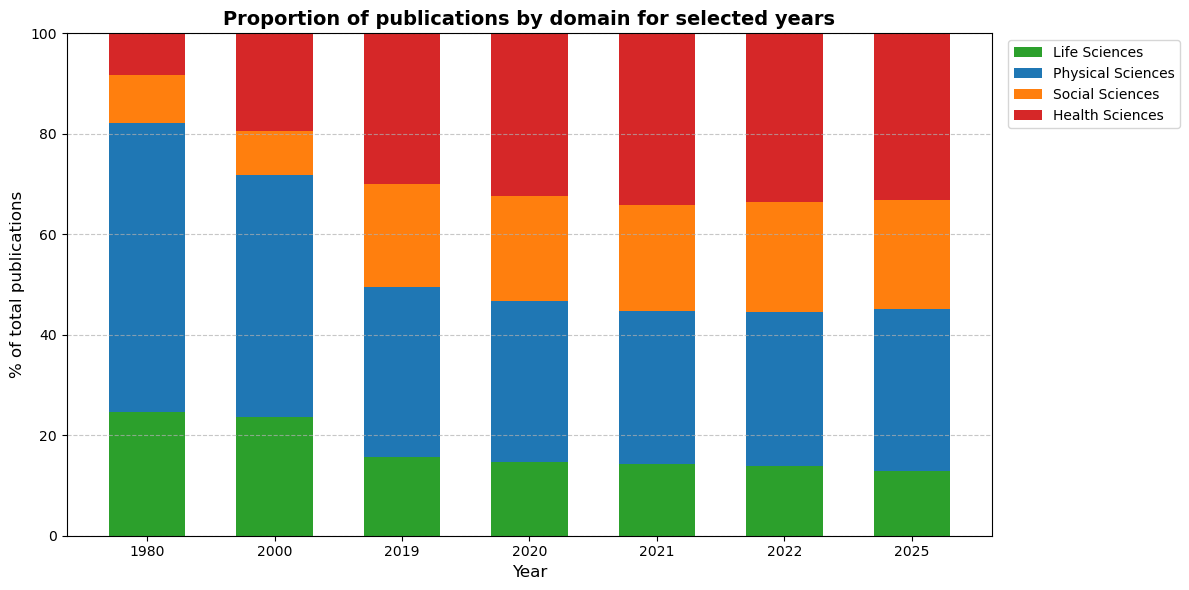

In [ ]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
order = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[order]

# YEARS WE WANT TO SHOW
anys_a_mostrar = [1980, 2000, 2019,2020,2021,2022, 2025]

taula_seleccio = taula_dominis.loc[taula_dominis.index.isin(anys_a_mostrar)]
taula_percent = taula_seleccio.div(taula_seleccio.sum(axis=1), axis=0) * 100

# PLOT
fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(taula_percent))
colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']
for i, col in enumerate(taula_percent.columns):
    ax.bar(taula_percent.index.astype(str), taula_percent[col], 
           bottom=bottom, label=col, color=colors[i], width=0.6)
    bottom += taula_percent[col].values
ax.set_title("Proportion of publications by domain for selected years", fontsize=14, fontweight='bold')
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("% of total publications", fontsize=12)
ax.set_ylim(0, 100) # Assegurem que l'eix Y vagi de 0 a 100
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1)) # Llegenda fora

plt.tight_layout()
plt.show()

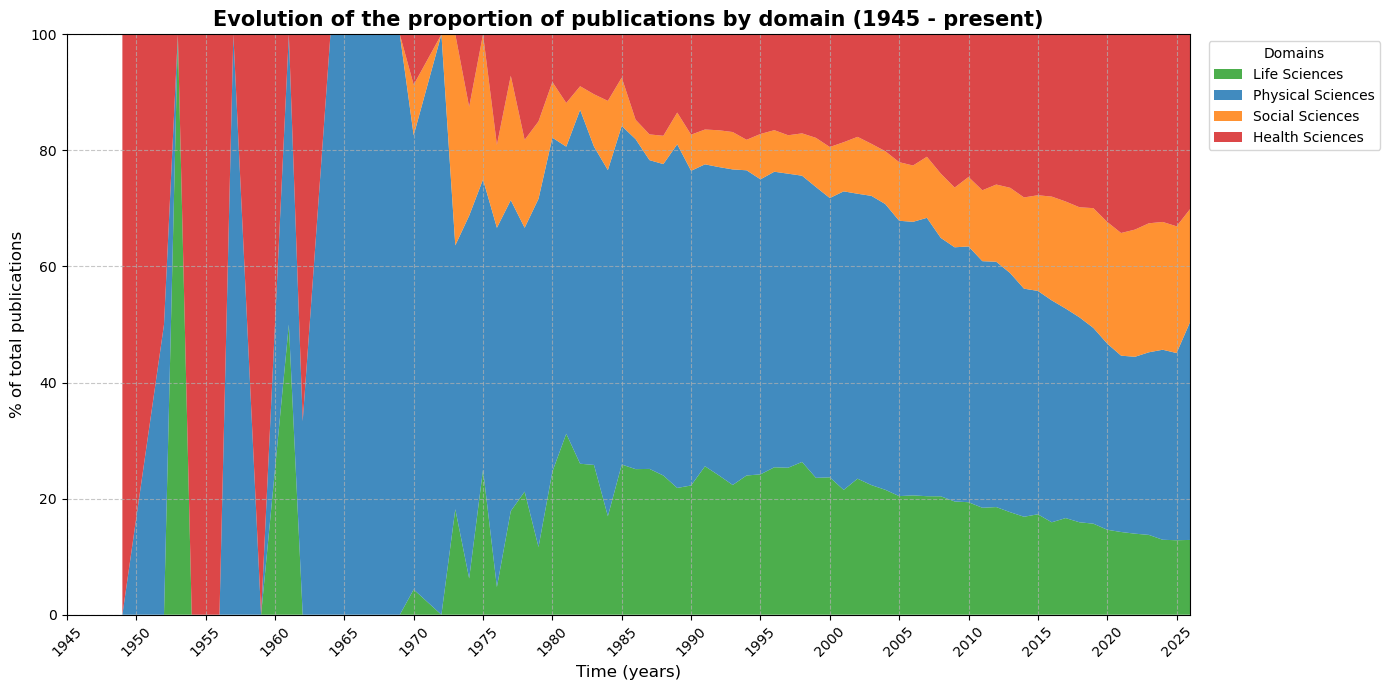

In [19]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
order = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[order]

# 🆕 FILTREM DES DEL 1945
# Ens assegurem que l'eix X comenci el 1945 (si hi ha dades prèvies, les ignorem)
taula_dominis = taula_dominis[taula_dominis.index >= 1945]

# 🆕 NORMALITZACIÓ (PER FILES)
# Dividim cada fila pel seu total i multipliquem per 100 per tenir percentatges
taula_percent = taula_dominis.div(taula_dominis.sum(axis=1), axis=0) * 100

anys = taula_percent.index
quantitats = [taula_percent[col].values for col in taula_percent.columns]
etiquetes = taula_percent.columns.tolist()

# 2. Creem el gràfic
fig, ax = plt.subplots(figsize=(14, 7))

colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']

# Dibuixem el stackplot amb els percentatges
ax.stackplot(anys, quantitats, labels=etiquetes, colors=colors, alpha=0.85)

# 3. Estil
ax.set_title("Evolution of the proportion of publications by domain (1945 - present)", 
             fontsize=15, fontweight='bold')
ax.set_xlabel("Time (years)", fontsize=12)
ax.set_ylabel("% of total publications", fontsize=12)

# Assegurem que l'eix Y vagi exactament de 0 a 100
ax.set_ylim(0, 100)
ax.set_xlim(1945, max(anys)) # Marquem l'inici a 1945

# Graella
ax.grid(True, linestyle='--', alpha=0.7)

# Anys de 5 en 5 a l'eix X
ticks_anys = np.arange(1945, max(anys) + 1, 5)
ax.set_xticks(ticks_anys)
ax.tick_params(axis='x', rotation=45)

# Llegenda a fora per no tapar les dades
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), title="Domains")

plt.tight_layout()
plt.show()

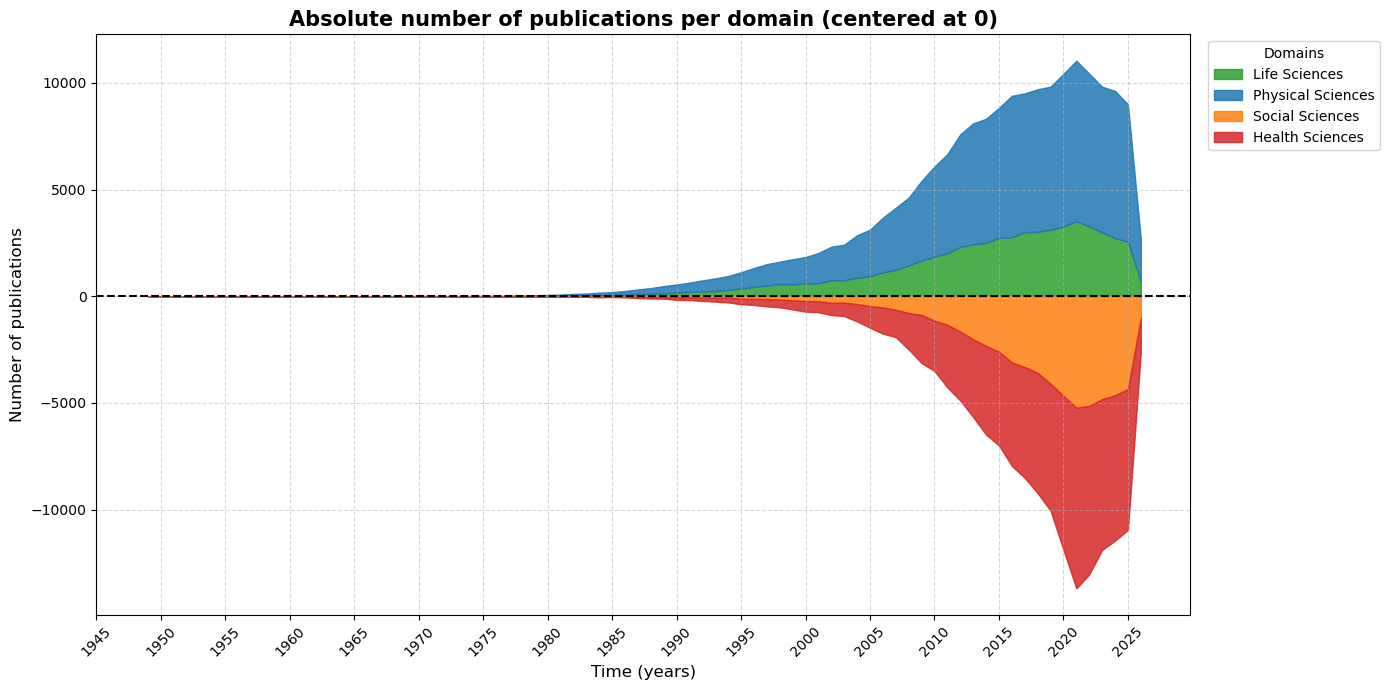

In [22]:
# 1. Carreguem i preparem les dades
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
order = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[order]

# Filtrem a partir del 1945
taula_dominis = taula_dominis[taula_dominis.index >= 1945]

# 🆕 AQUÍ NO NORMALITZEM! Agafem els volums absoluts directament
# (Ja no hi ha la línia que divideix pel total i multiplica per 100)

# 2. Separem en dos grups (els de dalt i els de baix)
dominis_dalt = ["Life Sciences", "Physical Sciences"]
dominis_baix = ["Social Sciences", "Health Sciences"]

anys = taula_dominis.index

# 3. Dibuixem
fig, ax = plt.subplots(figsize=(14, 7))

colors = {
    "Life Sciences": '#2ca02c', 
    "Physical Sciences": '#1f77b4', 
    "Social Sciences": '#ff7f0e', 
    "Health Sciences": '#d62728'
}

# --- PART DE DALT (Positius) ---
bottom_pos = np.zeros(len(anys))
for domini in dominis_dalt:
    valors = taula_dominis[domini].values
    ax.fill_between(anys, bottom_pos, bottom_pos + valors, 
                    label=domini, color=colors[domini], alpha=0.85)
    bottom_pos += valors

# --- PART DE BAIX (Negatius) ---
bottom_neg = np.zeros(len(anys))
for domini in dominis_baix:
    valors = taula_dominis[domini].values
    ax.fill_between(anys, bottom_neg, bottom_neg - valors, 
                    label=domini, color=colors[domini], alpha=0.85)
    bottom_neg -= valors

# 4. Estil del gràfic
ax.set_title("Absolute number of publications per domain (centered at 0)", 
             fontsize=15, fontweight='bold')
ax.set_xlabel("Time (years)", fontsize=12)
ax.set_ylabel("Number of publications", fontsize=12)

# Dibuixem la línia horitzontal del 0
ax.axhline(0, color='black', linewidth=1.5, linestyle='--')

# Ja no posem límits fixos de -100 a 100 a l'eix Y perquè els números seran molt més grans.
# Deixem que Matplotlib calculi els límits automàticament.

# Graella i anys de 5 en 5
ax.grid(True, linestyle='--', alpha=0.5)
ticks_anys = np.arange(1945, max(anys) + 1, 5)
ax.set_xticks(ticks_anys)
ax.tick_params(axis='x', rotation=45)

ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), title="Domains")

plt.tight_layout()
plt.show()

COSES A FER
- (_Escala log (eix y) com un insight (recta i creixement + gran al 2021)_)
- Mirar per mesos al 2020 (covid) --> les proporcions
- Mirar al covid com evolucionen les àrees que més shi relacionaven (psico,medicina...) / també es podria mirar
- Normalitzar be suma/Ntotal   (H-<H>)/(<H> o total), H/<H>
- (_Treure els anys <1995 quan siguin sorollosos i treure 2026_)

- Make figures and tables
- Write bullet points/explain as it you think loud

MINI-PAPER:
ordre: title (max 2 lines, 75 caract) --> it should provide some "results"
       abstract
       intro
       methods
       results/discussion
       conclusion

PRESENTACIÓ: 10-15 min. Comencem 10:00.

# COLLABORATIONS BETWEEN DOMAINS (NO!!!)

In [14]:
# 1. Carreguem el fitxer
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_unics = df.drop_duplicates(subset=["doi"]).copy()

# 2. Creem el diccionari de field a domain
fields = pd.read_parquet("../data/external/fields.parquet")
field_to_domain = dict(zip(fields["field_id"].astype(str), fields["domain_name"]))

# 3. Funció per obtenir la llista de dominis únics d'un paper
def get_domains(topics_list):
    if not isinstance(topics_list, (list, tuple)) or len(topics_list) == 0:
        return []
    
    # Traduïm cada field_id al seu domini
    domains = [field_to_domain.get(str(topic_id)) for topic_id in topics_list]
    
    # Traiem els Nuls i els duplicats (si un paper té 2 topics del mateix domini, només volem el domini 1 cop)
    domains_unics = list(set([d for d in domains if d is not None]))
    return domains_unics

# 4. Apliquem la funció a cada paper
df_unics["domains_involved"] = df_unics["topics_field_ids"].apply(get_domains)

# 5. Comptem les connexions (parelles de dominis)
connexions = Counter()

for domains in df_unics["domains_involved"]:
    if len(domains) > 1: # Si té més d'un domini, hi ha col·laboració
        # Generem totes les parelles possibles (ex: Life-Physical, Life-Health)
        parelles = list(itertools.combinations(sorted(domains), 2))
        connexions.update(parelles)

# 6. Convertim a una taula per veure-ho clar
df_connexions = pd.DataFrame(
    [(d1, d2, count) for (d1, d2), count in connexions.items()], 
    columns=["Domain 1", "Domain 2", "Count"]
).sort_values("Count", ascending=False)

print("Top col·laboracions entre dominis:")
display(df_connexions)

Top col·laboracions entre dominis:


,Domain 1,Domain 2,Count


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
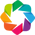

:Chord   [start,end]

In [15]:
import holoviews as hv
from holoviews import opts
hv.extension('bokeh')

# Creem la matriu per al Chord
# HoloViews necessita les dades en format (Origen, Destí, Valor)
# I li hem de sumar la suma dels dos sentits perquè el gràfic quedi simètric
chord_data = []
for index, row in df_connexions.iterrows():
    chord_data.append((row["Domain 1"], row["Domain 2"], row["Count"]))
    chord_data.append((row["Domain 2"], row["Domain 1"], row["Count"])) # Afegim el sentit invers

# Creem el gràfic
chord = hv.Chord(chord_data).opts(
    opts.Chord(cmap='Category20', edge_cmap='Category20', 
               labels='name', node_color='index',
               width=800, height=800,
               title="Collaboration between Domains (Shared Topics)")
)

# Mostrem el gràfic
chord

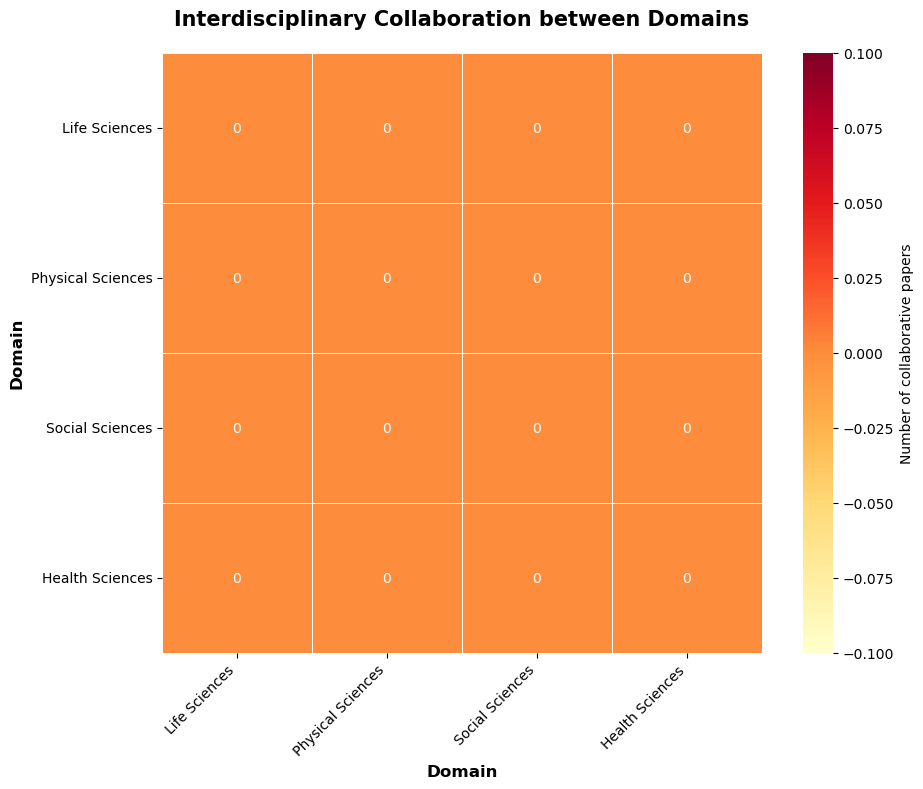

In [18]:
import seaborn as sns

# ==========================================
# 1. PROCESSAMENT DE LES DADES
# ==========================================
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_unics = df.drop_duplicates(subset=["doi"]).copy()

fields = pd.read_parquet("../data/external/fields.parquet")
field_to_domain = dict(zip(fields["field_id"].astype(str), fields["domain_name"]))

def get_domains(topics_list):
    if not isinstance(topics_list, (list, tuple)) or len(topics_list) == 0:
        return []
    domains = [field_to_domain.get(str(topic_id)) for topic_id in topics_list]
    return list(set([d for d in domains if d is not None]))

df_unics["domains_involved"] = df_unics["topics_field_ids"].apply(get_domains)

# Comptem les connexions (parelles)
connexions = Counter()
for domains in df_unics["domains_involved"]:
    if len(domains) > 1:
        parelles = list(itertools.combinations(sorted(domains), 2))
        connexions.update(parelles)

# ==========================================
# 2. CREACIÓ DE LA MATRIU SIMÈTRICA
# ==========================================
# Llista de dominis en l'ordre que ens agrada
ordre = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]

# Creem una matriu buida de 4x4
matriu = pd.DataFrame(0, index=ordre, columns=ordre)

# Omplim la matriu amb els resultats (la fem simètrica, posant el valor als dos costats)
for (dom1, dom2), count in connexions.items():
    matriu.loc[dom1, dom2] = count
    matriu.loc[dom2, dom1] = count

# La diagonal (on un domini es creua amb si mateix) no té gaire sentit per a les col·laboracions,
# així que la deixem a 0 (o la podríem omplir amb el total de papers d'aquell domini, però és enganyós).
np.fill_diagonal(matriu.values, 0)

# ==========================================
# 3. DIBUIX DEL HEATMAP
# ==========================================
plt.figure(figsize=(10, 8))

# Dibuixem el heatmap amb seaborn
# cmap='YlOrRd' fa servir una escala de groc a vermell (com més vermell, més col·laboració)
# annot=True posa els números a dins de cada quadre
sns.heatmap(matriu, 
            annot=True, 
            fmt='d', # 'd' és per format d'enters (sense decimals)
            cmap='YlOrRd', 
            linewidths=.5, 
            square=True,
            cbar_kws={'label': 'Number of collaborative papers'})

plt.title("Interdisciplinary Collaboration between Domains", fontsize=15, fontweight='bold', pad=20)
plt.xlabel("Domain", fontsize=12, fontweight='bold')
plt.ylabel("Domain", fontsize=12, fontweight='bold')

# Girem les etiquetes de l'eix X perquè es llegeixin bé
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [30]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")

# Mirem un paper que tingui dades
exemple = df[df['topics_field_ids'].notna()].iloc[0]['topics_field_ids']
print("Valor original:", exemple)
print("Tipus de dada:", type(exemple))

# Si és una llista, mirem el tipus de dins
if isinstance(exemple, (list, tuple)) and len(exemple) > 0:
    print("Tipus del primer element:", type(exemple[0]))
    print("Valor del primer element:", exemple[0])

Valor original: []
Tipus de dada: <class 'numpy.ndarray'>


# COVID

### Data processing

In [106]:
df_papers = pd.read_parquet(EXTERNAL / "papers_cleaned.gencat.parquet")

# Convertim la columna 'date' a format de data real
df_papers['date'] = pd.to_datetime(df_papers['date'])
# Creem les columnes 'year' i 'month'
df_papers['year'] = df_papers['date'].dt.year
df_papers['month'] = df_papers['date'].dt.month

# Eliminates duplicated dois
print("Publicacions AMB duplicats:",len(df_papers))
df_unics = df_papers.drop_duplicates(subset=["doi"]).copy()
print("Publicacions SENSE duplicats:",len(df_unics))

# Load data from fields and works
works = pd.read_parquet(DATA / "external/works.parquet", columns=["doi", "primary_topic_field_id"])
fields = pd.read_parquet(DATA / "external/fields.parquet")

# Eliminates duplicated full rows
print("Works AMB duplicats:",len(works))
works = works.drop_duplicates()
print("Works SENSE duplicats:",len(works))

# Prepare merge
fields["field_id"] = fields["field_id"].astype(str)
field_info = fields.set_index("field_id")[["field_name", "domain_name"]].to_dict(orient="index")

# Creuem els papers únics amb els seus topics
# Com que hi ha papers amb múltiples topics, farem un merge i després un "explode"
df_merged = df_unics.merge(works, on="doi", how="left")

# Cleans names
df_merged["primary_topic_field_id"] = df_merged["primary_topic_field_id"].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

# Names mapping
df_merged["topic_name"] = df_merged["primary_topic_field_id"].map(lambda x: field_info.get(x, {}).get("field_name"))
df_merged["domain_name"] = df_merged["primary_topic_field_id"].map(lambda x: field_info.get(x, {}).get("domain_name"))

# Filter data from 2019 to 2022
df_covid = df_merged[(df_merged["year"] >= 2019) & (df_merged["year"] <= 2022)].copy()

# Select only the desired columns
# 'year', 'month', 'doi' i les columnes d'enriquiment (topic_name, domain_name)
columnes_finals = ["year", "month", "doi", "topic_name", "domain_name"]
df_final = df_covid[columnes_finals]

# Save file
output_path = PROCESSED / "all_papers_enriched_covid.parquet"
df_final.to_parquet(output_path, index=False)

print(f"Dimensions: {df_final.shape[0]} files, {df_final.shape[1]} columnes")
print("\nPrimeres files:")
display(df_final.head())

Publicacions AMB duplicats: 1747707
Publicacions SENSE duplicats: 358039
Works AMB duplicats: 348417
Works SENSE duplicats: 348089
Dimensions: 88150 files, 5 columnes

Primeres files:


,year,month,doi,topic_name,domain_name
201902,2019,1,10.1093/sleep/zsy205,Psychology,Social Sciences
201903,2019,1,10.1109/tcomm.2018.2876295,Computer Science,Physical Sciences
201904,2019,1,10.1016/j.jchf.2019.04.022,Medicine,Health Sciences
201905,2019,1,10.1016/j.phrs.2018.11.032,"Biochemistry, Genetics and Molecular Biology",Life Sciences
201906,2019,1,10.1111/jsr.12830,Medicine,Health Sciences


Rows without topics/domains are deleted

In [107]:
df = pd.read_parquet("../data/processed/all_papers_enriched_covid.parquet")

# Count rows
total_files = len(df)
files_amb_topic = df["topic_name"].notna().sum()
files_sense_topic = df["topic_name"].isna().sum()

print(f"Total de files al fitxer: {total_files}")
print(f"Files AMB topic: {files_amb_topic}")
print(f"Files SENSE topic (None): {files_sense_topic}")
print(f"Percentatge de files sense topic: {(files_sense_topic / total_files) * 100:.2f}%")

# Mirem alguns exemples de papers que s'han quedat sense topic
print("\nExemples de files sense topic:")
display(df[df["topic_name"].isna()].head(5))

Total de files al fitxer: 88150
Files AMB topic: 86032
Files SENSE topic (None): 2118
Percentatge de files sense topic: 2.40%

Exemples de files sense topic:


,year,month,doi,topic_name,domain_name
89,2019,1,10.5277/abb-01300-2019-02,None,None
116,2019,1,10.3389/fevo.2019.180,None,None
123,2019,1,10.2436/20.1502.01.3,None,None
166,2019,1,10.13137/1825-5167/28382,None,None
188,2019,1,10.4317/jced.55326.ecollection2019jan,None,None


### Plot _: publicacions 2019-2022

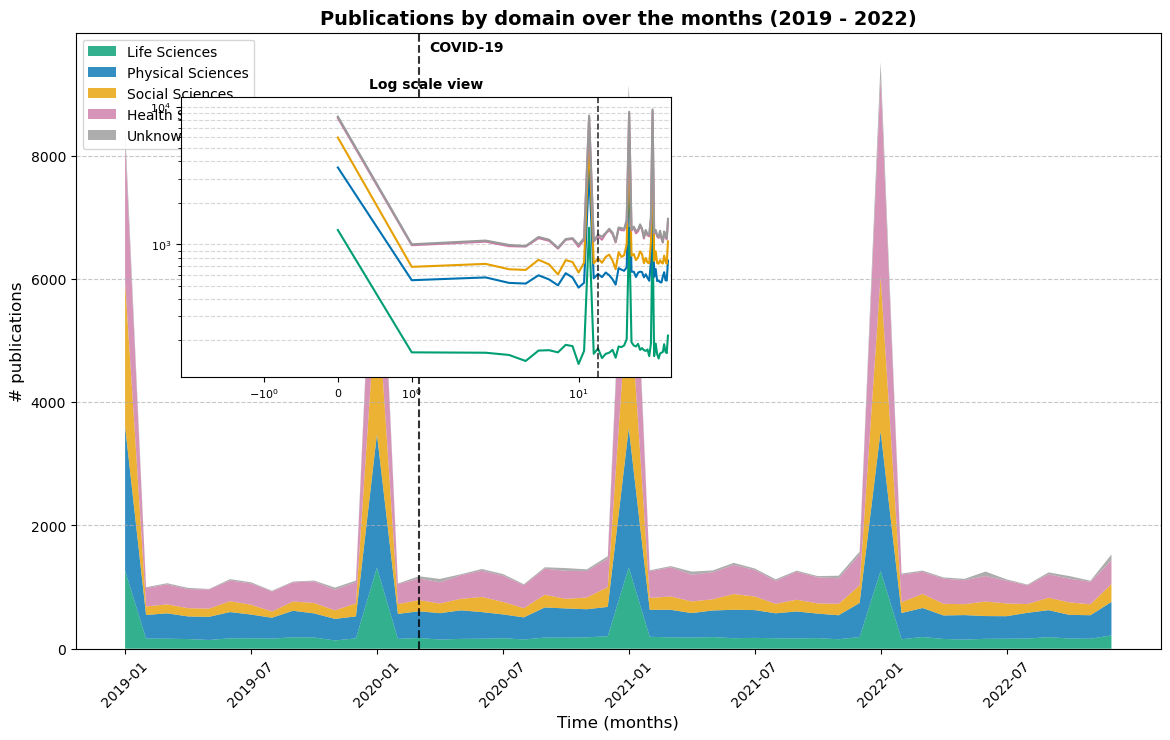

In [108]:
df = pd.read_parquet("../data/processed/all_papers_enriched_covid.parquet")

# New category: UNKNOWN (for topics we dont know)
df["domain_name"] = df["domain_name"].fillna("Unknown")

# 🆕 Creem una columna de data contínua (Any-Mes) per a l'eix X
df["date_month"] = pd.to_datetime(df["year"].astype(str) + "-" + df["month"].astype(str).str.zfill(2))

colors = {'Life Sciences': '#009E73','Physical Sciences': '#0072B2','Social Sciences': '#E69F00',
    'Health Sciences': '#CC79A7','Unknown': '#999999'}

# Only papers with domain assigned (ara tots en tenen, però si vols treure algun altre, ho pots fer aquí)
df_plots = df.copy()

# Eliminate DOI duplicated publications (Opcional, el tens comentat al teu original)
#df_plots = df_plots.drop_duplicates(subset=["doi", "date_month"])

# Create table for the plot: Files = Mesos, Columnes = Dominis, Valors = Nombre de papers
taula_dominis = df_plots.groupby(["date_month", "domain_name"]).size().unstack(fill_value=0)

# Ordenem les columnes (afegint Unknown al final)
order = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences", "Unknown"]
# Ens assegurem que només agafem les columnes que existeixen al df per evitar errors
order = [col for col in order if col in taula_dominis.columns]
taula_dominis = taula_dominis[order] 

# NO FILTREM PER ANYS, JA QUE EL FITXER JA NOMÉS TÉ EL 2019-2022

# Creem un índex numèric per a l'eix X perquè el stackplot no accepta dates directament
x_vals = np.arange(len(taula_dominis.index))

# Guardem les etiquetes de text (els mesos) per posar-los després a l'eix
etiquetes_mesos = [d.strftime('%Y-%m') for d in taula_dominis.index]

quantitats = [taula_dominis[col].values for col in taula_dominis.columns]
etiquetes = taula_dominis.columns.tolist()

colors_list = [colors[col] for col in etiquetes]

cumsum = taula_dominis.cumsum(axis=1)

# PLOT
fig = plt.figure(figsize=(14, 8)) 
ax_main = fig.add_subplot(111)   

ax_main.stackplot(x_vals, quantitats, labels=etiquetes, colors=colors_list, alpha=0.8)
ax_main.set_title("Publications by domain over the months (2019 - 2022)", fontsize=14, fontweight='bold')
ax_main.set_xlabel("Time (months)", fontsize=12)
ax_main.set_ylabel("# publications", fontsize=12)
ax_main.grid(axis='y', linestyle='--', alpha=0.7)
ax_main.legend(loc='upper left')

# Show WHEN COVID STARTS (Març de 2020)
# Busquem l'índex on comença el 2020-03
try:
    index_covid = etiquetes_mesos.index('2020-03')
    ax_main.axvline(x=index_covid, color='black', linestyle='--', linewidth=1.5, alpha=0.8)
    ax_main.text(index_covid + 0.5, ax_main.get_ylim()[1]*0.97, 'COVID-19', color='black', fontsize=10, fontweight='bold')
except ValueError:
    pass # Si no troba el mes, no dibuixa la línia

# Inset
ax_inset = fig.add_axes([0.2, 0.45, 0.35, 0.35]) 
for i, col in enumerate(cumsum.columns):
    # Li passem l'x_vals (números enters) perquè funcioni bé amb l'escala logarítmica de l'eix X
    ax_inset.plot(x_vals, cumsum[col], color=colors_list[i], linewidth=1.5)

ax_inset.set_yscale('log')
ax_inset.set_xscale('symlog') # 🆕 symlog és millor que log per a l'eix X perquè l'índex 0 dona error a log
ax_inset.set_title("Log scale view", fontsize=10, fontweight='bold')
ax_inset.grid(axis="y", linestyle='--', alpha=0.5, which='both') 
ax_inset.tick_params(axis='both', labelsize=8)

# Line to indicate COVID-19 in the inset
try:
    ax_inset.axvline(x=index_covid, color='black', linestyle='--', linewidth=1.2, alpha=0.8)
except NameError:
    pass

# Personalized axis: we want to show months and years
# Ho posem cada 6 mesos per no saturar
ticks_posicions = np.arange(0, len(x_vals), 6)
ticks_etiquetes = [etiquetes_mesos[i] for i in ticks_posicions]

ax_main.set_xticks(ticks_posicions)
ax_main.set_xticklabels(ticks_etiquetes, rotation=45)

# SAVE PLOT
output_dir = "../plots/alba"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/area_chart_publications_by_domain_months.png", dpi=300, bbox_inches='tight')

plt.show()

This figure shows that the data we have don't really have usefull informacion about the papers publication date. This is probably because most of the publications didn't have this information in the Gencat open data web and, therefore, all the unsure dates were automatically classified at the beaggining of each year (january).